In [2]:
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import os 
from padelpy import padeldescriptor
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from rdkit.Chem import rdFingerprintGenerator  
import pandas as pd 
from padelpy import from_smiles
import warnings
warnings.filterwarnings('ignore')

In [3]:
from rdkit import Chem
from rdkit.Chem import AllChem
import numpy as np

df = pd.read_csv('cleaned_data.csv')
df.head()

,SMILES,VERIFY,ESOL Class,MW_pub,BBB,hERG,Ames,H-HT
0,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,False,Moderately soluble,468.4,0.982377,0.138762,0.684111,0.349169
1,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,False,Moderately soluble,476.3,0.999029,0.262471,0.351038,0.586856
2,B1(OC(C(O1)(C)C)(C)C)C2=CC3=C(CC4(C35C(=O)N(C(...,True,Moderately soluble,472.4,0.989686,0.112066,0.887385,0.556827
3,C#CCOC1=CN=C(C=C1)C(=O)NC2=CC(=C(C(=C2)F)F)[C@...,True,Moderately soluble,486.4,0.001523,0.666432,0.854345,0.977018
4,C#CCOC1=CN=C(C=C1)C(=O)NC2=CC(=C(C=C2)F)[C@@]3...,False,Soluble,430.4,0.004441,0.332171,0.871076,0.912706


In [4]:
df['ESOL Class'].value_counts()

ESOL Class
Moderately soluble    1070
Soluble                788
Poorly soluble           2
Name: count, dtype: int64

In [5]:
# Filter the dataframe to exclude 'Poorly soluble'
df = df[df['ESOL Class'] != 'Poorly soluble']

In [6]:
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
import numpy as np

# morgan_gen = GetMorganGenerator(radius=2, fpSize=1024)

# def smiles_to_features(smiles):
#     mol = Chem.MolFromSmiles(smiles)
#     if mol is None:
#         return None
#     fp = morgan_gen.GetFingerprintAsNumPy(mol)
#     return fp
# df['features'] = df['SMILES'].apply(smiles_to_features)




import numpy as np
import pandas as pd
from padelpy import from_smiles

def smiles_to_padel_features(smiles):
    """
    Calculates PaDEL descriptors for a given SMILES string.
    By default, this computes standard 2D descriptors.
    """
    try:
        # from_smiles returns a dictionary of descriptors
        # e.g., {'nAcid': '0', 'ALogP': '1.23', ...}
        descriptors = from_smiles(smiles, fingerprints=False)
        
        # Convert the dictionary values to float numbers in a NumPy array
        # Missing values/errors will default to 0.0
        fp = np.array([float(val) for val in descriptors.values()], dtype=np.float32)
        return fp
    except Exception as e:
        # Catches invalid SMILES or PaDEL processing failures
        return None

# Apply to your dataframe
df['features'] = df['SMILES'].apply(smiles_to_padel_features)

High-dimensional dataset (1024 features). Some models may be slow or fail. Consider dimensionality reduction.


=== LAZYPREDICT MODEL SUMMARY ===
                             Accuracy  Balanced Accuracy   ROC AUC  F1 Score  \
Model                                                                          
LogisticRegression           0.932796           0.931191  0.969474  0.932770   
Perceptron                   0.932796           0.928984  0.967031  0.932597   
PassiveAggressiveClassifier  0.924731           0.924818  0.960172  0.924833   
SGDClassifier                0.932796           0.924568  0.970328  0.932136   
LinearSVC                    0.922043           0.920977  0.957140  0.922071   
CalibratedClassifierCV       0.924731           0.920403  0.959583  0.924473   
ExtraTreesClassifier         0.922043           0.916561  0.975818  0.921655   
XGBClassifier                0.916667           0.911086  0.960378  0.916251   
LGBMClassifier               0.913978           0.908716  0.967355  0.913596   
RandomForestClassifier       0.913978           0.907980  0.957846  0.913503   
Decisi

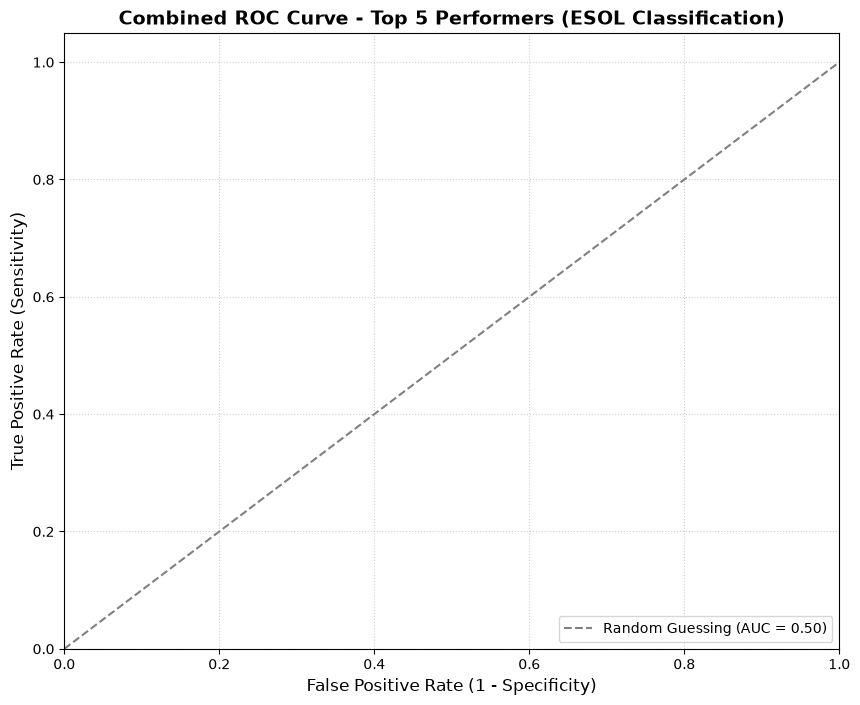

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_curve, auc
from lazypredict.Supervised import LazyClassifier

# --- 1. Prepare Data (As cleaned in previous steps) ---
df_clean = df.dropna(subset=['features']).copy()
X = np.stack(df_clean['features'].values)

le_esol = LabelEncoder()
y = le_esol.fit_transform(df_clean['ESOL Class']) # Binary: 0 and 1

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- 2. Run LazyClassifier to evaluate all algorithms ---
# We use predictions=True so that lazypredict returns the internal trained model estimators
clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None, predictions=True)
models_summary, predictions_df = clf.fit(X_train, X_test, y_train, y_test)

# Print the comparison table (Shows Accuracy, Balanced Accuracy, ROC AUC, F1 Score)
print("=== LAZYPREDICT MODEL SUMMARY ===")
print(models_summary)

# --- 3. Extract Top Models & Generate Combined ROC Curve ---
# Grab the names of the top 5 models sorted by ROC AUC / Accuracy
top_5_model_names = models_summary.index[:5].tolist()

plt.figure(figsize=(10, 8))

print("\nGenerating ROC curves for the top 5 models...")
# Retrieve model dictionary directly from the lazypredict object container
fitted_models = clf.models

for name in top_5_model_names:
    model = fitted_models[name]
    
    # Not all classifiers support predict_proba (e.g., RidgeClassifier, LinearSVC)
    # So we use decision_function as a fallback if predict_proba isn't available
    try:
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_test)[:, 1]
        elif hasattr(model, "decision_function"):
            y_score = model.decision_function(X_test)
        else:
            # If the model doesn't output continuous scores, fallback to binary predictions
            y_score = model.predict(X_test)
            
        fpr, tpr, _ = roc_curve(y_test, y_score)
        roc_auc = auc(fpr, tpr)
        
        # Plot individual model line
        plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')
        
    except Exception as e:
        # Skip gracefully if a specific model fails to generate threshold scores
        print(f"Could not compute ROC curve for {name}. Skipping.")
        continue

# Plot the baseline diagonal reference line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Guessing (AUC = 0.50)')

# Aesthetics and formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Combined ROC Curve - Top 5 Performers (ESOL Classification)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

Training and evaluating Logistic Regression...
Training and evaluating Calibrated Classifier...
Training and evaluating Extra Trees...
Training and evaluating LightGBM...
Training and evaluating XGBoost...
Training and evaluating Random Forest...
Training and evaluating SVM (RBF Kernel)...
Training and evaluating K-Neighbors (KNN)...


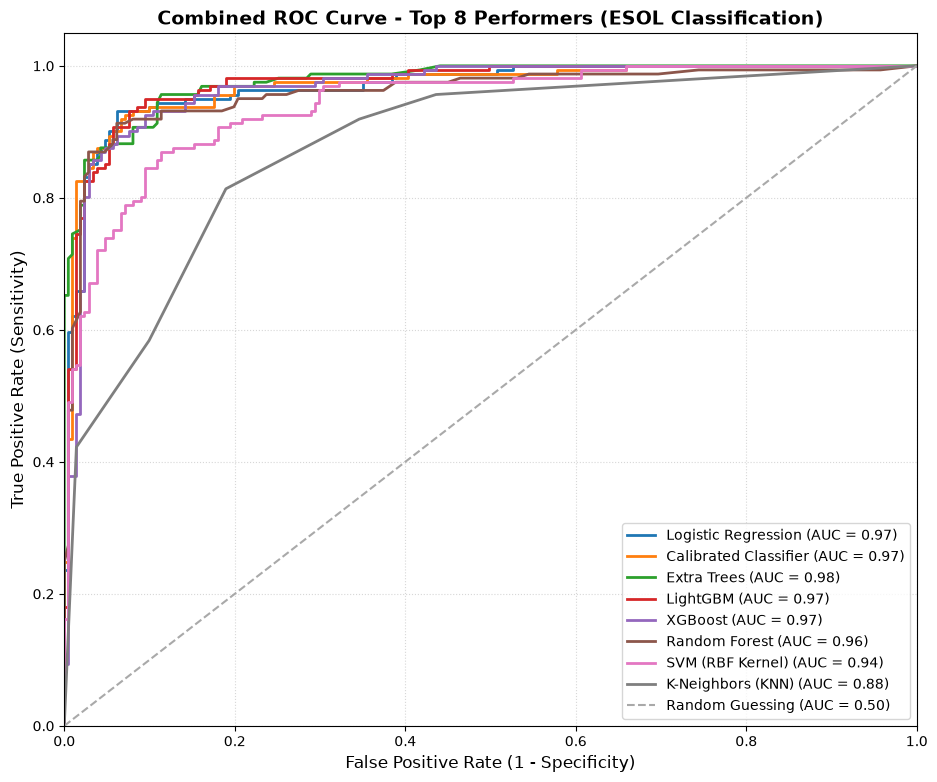

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_curve, auc

# --- Import all 8 Classifiers ---
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
# The 3 new additions:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# --- Prepare Data ---
df_clean = df.dropna(subset=['features']).copy()
X = np.stack(df_clean['features'].values)

le_esol = LabelEncoder()
y = le_esol.fit_transform(df_clean['ESOL Class'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Define the Expanded 8-Model Dictionary ---
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Calibrated Classifier': CalibratedClassifierCV(n_jobs=-1), # New 1
    'Extra Trees': ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=200, random_state=42, verbose=-1),
    'XGBoost': XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss'),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'SVM (RBF Kernel)': SVC(probability=True, random_state=42), # New 2
    'K-Neighbors (KNN)': KNeighborsClassifier(n_neighbors=5, n_jobs=-1) # New 3
}

# --- Plotting ---
plt.figure(figsize=(11, 9))

for name, model in models.items():
    print(f"Training and evaluating {name}...")
    # Train
    model.fit(X_train, y_train)
    
    # Extract clean probability scores for the positive class (Soluble)
    y_score = model.predict_proba(X_test)[:, 1]
    
    # Compute metrics
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    
    # Build the line
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')

# Baseline diagonal line
plt.plot([0, 1], [0, 1], color='darkgray', linestyle='--', lw=1.5, label='Random Guessing (AUC = 0.50)')

# Aesthetics
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Combined ROC Curve - Top 8 Performers (ESOL Classification)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.5)

plt.show()

Original dataset size: 1858
Deduplicated dataset size: 1262


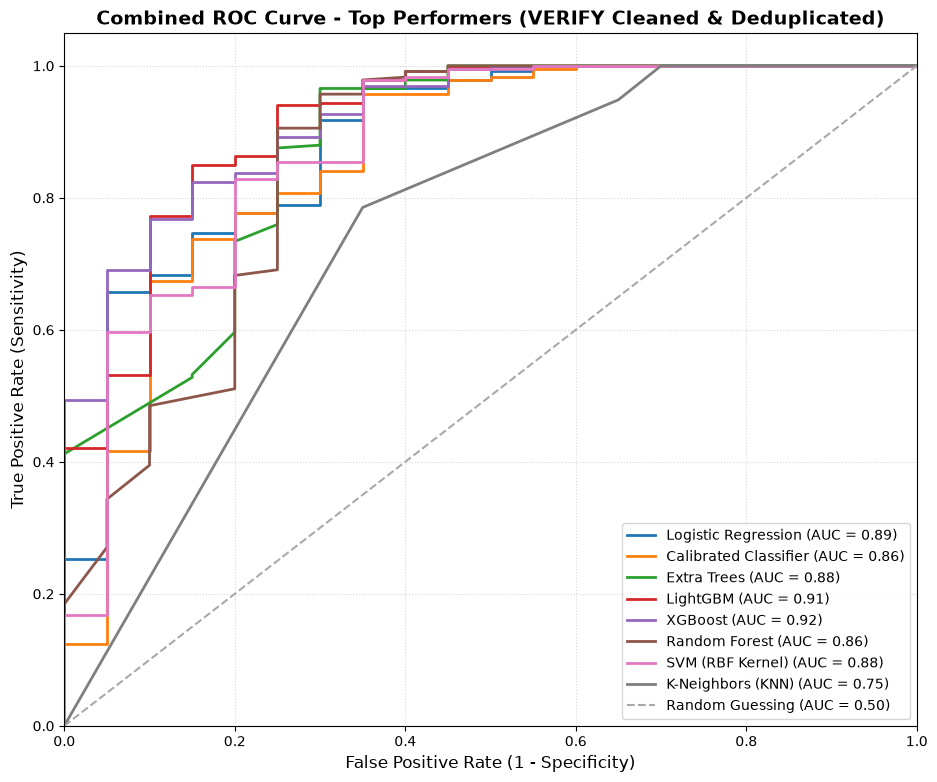

In [ ]:
# Before training a structural model on fingerprints, we must resolve these duplicate SMILES.
# We can do this by grouping by SMILES and taking the majority vote (or mean)
# for the VERIFY column so each unique molecule has exactly one ground-truth answer.


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# --- 1. Resolve Conflicting Labels & Deduplicate ---
# Convert VERIFY to numeric binary entries first
df['VERIFY_numeric'] = df['VERIFY'].apply(lambda x: 1 if x is True or str(x).lower() == 'true' else 0)

# Group by SMILES and take the average label. If it's > 0.5, the majority is True (1), else False (0)
df_dedup = df.groupby('SMILES').agg({
    'VERIFY_numeric': lambda x: 1 if x.mean() >= 0.5 else 0
}).reset_index()

print(f"Original dataset size: {len(df)}")
print(f"Deduplicated dataset size: {len(df_dedup)}")

# --- 2. Regenerate Clean Features ---
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

morgan_gen = GetMorganGenerator(radius=2, fpSize=1024)

def smiles_to_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return morgan_gen.GetFingerprintAsNumPy(mol)

df_dedup['features'] = df_dedup['SMILES'].apply(smiles_to_features)
df_clean = df_dedup.dropna(subset=['features']).copy()

X = np.stack(df_clean['features'].values)
y_verify = df_clean['VERIFY_numeric'].values

# Stratified split to keep perfect class balances
X_train, X_test, y_train, y_test = train_test_split(
    X, y_verify, test_size=0.2, random_state=42, stratify=y_verify
)

# --- 3. Evaluate and Plot ---
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Calibrated Classifier': CalibratedClassifierCV(n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=200, class_weight='balanced', random_state=42, verbose=-1),
    'XGBoost': XGBClassifier(n_estimators=200, random_state=42, eval_metric='logloss'),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    'SVM (RBF Kernel)': SVC(probability=True, class_weight='balanced', random_state=42),
    'K-Neighbors (KNN)': KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
}

plt.figure(figsize=(11, 9))

for name, model in models.items():
    model.fit(X_train, y_train)
    
    # Reliably grab class 1 index
    pos_idx = list(model.classes_).index(1) if hasattr(model, 'classes_') else 1
    y_score = model.predict_proba(X_test)[:, pos_idx]
    
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='darkgray', linestyle='--', lw=1.5, label='Random Guessing (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Combined ROC Curve - Top Performers (VERIFY Cleaned & Deduplicated)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

In [30]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# --- Define evaluation storage ---
metrics_list = []

print("Calculating full performance metrics for the top models...")

for name, model in models.items():
    # 1. Generate hard binary predictions (0 or 1)
    y_pred = model.predict(X_test)
    
    # 2. Compute individual metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    # We can pull the exact AUC calculated previously from the plot steps
    # Or quickly recalculate it here for the table
    pos_idx = list(model.classes_).index(1) if hasattr(model, 'classes_') else 1
    y_score = model.predict_proba(X_test)[:, pos_idx]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    
    # 3. Append results
    metrics_list.append({
        'Model Name': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall (Sensitivity)': rec,
        'F1-Score': f1,
        'ROC AUC': roc_auc
    })

# --- 3. Convert to a formatted DataFrame ---
df_metrics = pd.DataFrame(metrics_list)
df_metrics = df_metrics.sort_values(by='ROC AUC', ascending=False).reset_index(drop=True)

# Format numbers to 3 decimal places for clean reporting
print("\n" + "="*75)
print("             FINAL MODEL EVALUATION PERFORMANCE (VERIFY TARGET)         ")
print("="*75)
print(df_metrics.to_string(index=False, formatters={
    'Accuracy': '{:,.3f}'.format,
    'Precision': '{:,.3f}'.format,
    'Recall (Sensitivity)': '{:,.3f}'.format,
    'F1-Score': '{:,.3f}'.format,
    'ROC AUC': '{:,.3f}'.format
}))
print("="*75)

Calculating full performance metrics for the top models...

             FINAL MODEL EVALUATION PERFORMANCE (VERIFY TARGET)         
           Model Name Accuracy Precision Recall (Sensitivity) F1-Score ROC AUC
              XGBoost    0.957     0.963                0.991    0.977   0.918
             LightGBM    0.960     0.967                0.991    0.979   0.915
  Logistic Regression    0.913     0.969                0.936    0.952   0.886
     SVM (RBF Kernel)    0.929     0.969                0.953    0.961   0.879
          Extra Trees    0.957     0.963                0.991    0.977   0.875
Calibrated Classifier    0.953     0.955                0.996    0.975   0.862
        Random Forest    0.957     0.966                0.987    0.977   0.856
    K-Neighbors (KNN)    0.945     0.943                1.000    0.971   0.746


In [1]:
# ##################################################
#                                 BBBB 
# ################################################

In [41]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import QuantileTransformer
from lightgbm import LGBMRegressor

# --- RDKit Imports ---
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
from rdkit.Chem import Descriptors

# --- 1. Resolve Duplicate Structures & Deduplicate ---
# Group by SMILES and aggregate the continuous BBB column by its mean value
df_dedup = df.groupby('SMILES').agg({
    'BBB': 'mean'
}).reset_index()

print(f"Original dataset size: {len(df)}")
print(f"Deduplicated dataset size: {len(df_dedup)}")

# --- 2. Regenerate Advanced Hybrid Features ---
# Expanded fingerprint to 2048-bit to map structural fragments cleanly
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

def extract_molecular_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    
    # Structural features
    fp = morgan_gen.GetFingerprintAsNumPy(mol)
    
    # Physical-chemical descriptors critical to passive BBB crossing
    phys_chem = np.array([
        Descriptors.MolLogP(mol),       # Lipophilicity
        Descriptors.TPSA(mol),          # Topological Polar Surface Area
        Descriptors.MolWt(mol),         # Molecular Weight
        Descriptors.NumHDonors(mol),    # Hydrogen Bond Donors
        Descriptors.NumHAcceptors(mol)  # Hydrogen Bond Acceptors
    ])
    
    return np.concatenate([fp, phys_chem])

# Apply and drop rows with invalid SMILES
df_dedup['features'] = df_dedup['SMILES'].apply(extract_molecular_features)
df_clean = df_dedup.dropna(subset=['features']).copy()

X = np.stack(df_clean['features'].values)
y_bbb = df_clean['BBB'].values

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_bbb, test_size=0.2, random_state=42)

# --- 3. Define the Tuned LightGBM Architecture ---
# Configured specifically for wide sparse arrays paired with dense numeric properties
tuned_lgb = LGBMRegressor(
    n_estimators=400,        # Increased tree count paired with a lower learning rate
    learning_rate=0.03,      # Gradual optimization steps to prevent overshooting
    num_leaves=24,           # Controlled tree size to prevent memorizing rare fragments
    subsample=0.8,           # Row bagging adds variance resilience
    colsample_bytree=0.7,    # Forces the tree to select physical descriptors by masking fingerprints
    min_child_samples=15,    # Disallows splitting down to tiny, noisy leaf samples
    random_state=42,
    verbose=-1
)

# --- 4. Target Quantile Mapping ---
# Maps the BBB distribution to a normal curve during loss calculation, 
# preventing the model from losing performance on target boundary clusters.
optimized_model = TransformedTargetRegressor(
    regressor=tuned_lgb,
    transformer=QuantileTransformer(output_distribution='normal', random_state=42)
)

# --- 5. Train and Collect Metrics ---
print("\nTraining and evaluating the optimized hybrid LightGBM model...")
optimized_model.fit(X_train, y_train)

# Predict continuous values
y_pred = optimized_model.predict(X_test)

# Compute regression measurements
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# --- 6. Generate Performance Scorecard ---
print("\n" + "="*80)
print("             FINAL MODEL REGRESSION PERFORMANCE (BBB TARGET)             ")
print("="*80)
print(f"Model Name: Optimized Hybrid LightGBM")
print(f"MSE:        {mse:,.4f}")
print(f"RMSE:       {rmse:,.4f}")
print(f"MAE:        {mae:,.4f}")
print(f"R2 Score:   {r2:,.4f}")
print("="*80)

Original dataset size: 1858
Deduplicated dataset size: 1262

Training and evaluating the optimized hybrid LightGBM model...

             FINAL MODEL REGRESSION PERFORMANCE (BBB TARGET)             
Model Name: Optimized Hybrid LightGBM
MSE:        0.0284
RMSE:       0.1684
MAE:        0.0930
R2 Score:   0.6635


In [44]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# --- Import LazyPredict ---
from lazypredict.Supervised import LazyRegressor

# --- RDKit Imports ---
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
from rdkit.Chem import Descriptors

# --- 1. Resolve Duplicate Structures & Deduplicate ---
df_dedup = df.groupby('SMILES').agg({'BBB': 'mean'}).reset_index()

print(f"Original dataset size: {len(df)}")
print(f"Deduplicated dataset size: {len(df_dedup)}")

# --- 2. Regenerate Advanced Hybrid Features ---
# 2048-bit fingerprint + 5 core physical-chemical properties
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

def extract_molecular_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    
    # Structural features
    fp = morgan_gen.GetFingerprintAsNumPy(mol)
    
    # Physical-chemical descriptors
    phys_chem = np.array([
        Descriptors.MolLogP(mol),       
        Descriptors.TPSA(mol),          
        Descriptors.MolWt(mol),         
        Descriptors.NumHDonors(mol),    
        Descriptors.NumHAcceptors(mol)  
    ])
    
    return np.concatenate([fp, phys_chem])

df_dedup['features'] = df_dedup['SMILES'].apply(extract_molecular_features)
df_clean = df_dedup.dropna(subset=['features']).copy()

X = np.stack(df_clean['features'].values)
y_bbb = df_clean['BBB'].values

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_bbb, test_size=0.2, random_state=42)

# --- 3. Run LazyRegressor across all models ---
print("\nInitializing LazyRegressor. Brute-forcing 30+ regression architectures...")

# ignore_warnings=True keeps the output stream clean from convergence/deprecation warnings
reg = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None)

# Run the fit pipeline
models, predictions = reg.fit(X_train, X_test, y_train, y_test)

# --- 4. Generate Performance Scorecard ---
print("\n" + "="*80)
print("             LAZYPREDICT COMPREHENSIVE PERFORMANCE LEADERBOARD            ")
print("="*80)
# This will display Adjusted R-Squared, R-Squared, RMSE, and Time Taken for all models
print(models)
print("="*80)

Original dataset size: 1858
Deduplicated dataset size: 1262


High-dimensional dataset (2053 features). Some models may be slow or fail. Consider dimensionality reduction.



Initializing LazyRegressor. Brute-forcing 30+ regression architectures...

             LAZYPREDICT COMPREHENSIVE PERFORMANCE LEADERBOARD            
                               Adjusted R-Squared  R-Squared      RMSE  \
Model                                                                    
AdaBoostRegressor                        1.130369   0.068276  0.280193   
TransformedTargetRegressor               1.125823   0.100768  0.275264   
LinearRegression                         1.125823   0.100768  0.275264   
LinearSVR                                1.121587   0.131041  0.270591   
LarsCV                                   1.112664   0.194808  0.260473   
Ridge                                    1.100615   0.280925  0.246150   
DecisionTreeRegressor                    1.093069   0.334852  0.236740   
ExtraTreeRegressor                       1.088764   0.365621  0.231200   
OrthogonalMatchingPursuit                1.085629   0.388024  0.227081   
RidgeCV                            

In [ ]:
# ##################################################
#                                 hERG  
# ################################################

In [45]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# --- Import LazyPredict ---
from lazypredict.Supervised import LazyRegressor

# --- RDKit Imports ---
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
from rdkit.Chem import Descriptors

# --- 1. Resolve Duplicate Structures & Deduplicate (Targeting hERG) ---
# Filter missing rows specific to hERG, then group and average continuous values
df_target = df.dropna(subset=['SMILES', 'hERG']).copy()
df_dedup = df_target.groupby('SMILES').agg({'hERG': 'mean'}).reset_index()

print(f"Original dataset size with hERG values: {len(df_target)}")
print(f"Deduplicated dataset size (hERG): {len(df_dedup)}")

# --- 2. Regenerate Advanced Hybrid Features ---
# 2048-bit fingerprint + 5 core physical-chemical properties
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

def extract_molecular_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    
    # Structural features
    fp = morgan_gen.GetFingerprintAsNumPy(mol)
    
    # Physical-chemical descriptors
    phys_chem = np.array([
        Descriptors.MolLogP(mol),       
        Descriptors.TPSA(mol),          
        Descriptors.MolWt(mol),         
        Descriptors.NumHDonors(mol),    
        Descriptors.NumHAcceptors(mol)  
    ])
    
    return np.concatenate([fp, phys_chem])

df_dedup['features'] = df_dedup['SMILES'].apply(extract_molecular_features)
df_clean = df_dedup.dropna(subset=['features']).copy()

X = np.stack(df_clean['features'].values)
y_herg = df_clean['hERG'].values

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_herg, test_size=0.2, random_state=42)

# --- 3. Run LazyRegressor across all models ---
print("\nInitializing LazyRegressor. Brute-forcing 30+ regression architectures on hERG...")

# ignore_warnings=True keeps the output stream clean from convergence/deprecation warnings
reg = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None)

# Run the fit pipeline
models, predictions = reg.fit(X_train, X_test, y_train, y_test)

# --- 4. Generate Performance Scorecard ---
print("\n" + "="*80)
print("             LAZYPREDICT COMPREHENSIVE PERFORMANCE LEADERBOARD (hERG)            ")
print("="*80)
# This will display Adjusted R-Squared, R-Squared, RMSE, and Time Taken for all models
print(models)
print("="*80)

Original dataset size with hERG values: 1858
Deduplicated dataset size (hERG): 1262


High-dimensional dataset (2053 features). Some models may be slow or fail. Consider dimensionality reduction.



Initializing LazyRegressor. Brute-forcing 30+ regression architectures on hERG...

             LAZYPREDICT COMPREHENSIVE PERFORMANCE LEADERBOARD (hERG)            
                               Adjusted R-Squared  R-Squared      RMSE  \
Model                                                                    
LarsCV                                   1.104004   0.256699  0.191656   
KNeighborsRegressor                      1.080949   0.421472  0.169084   
AdaBoostRegressor                        1.078639   0.437981  0.166654   
ExtraTreeRegressor                       1.060096   0.570501  0.145687   
DecisionTreeRegressor                    1.060066   0.570717  0.145650   
ExtraTreesRegressor                      1.053279   0.619222  0.137175   
SVR                                      1.052818   0.622520  0.136580   
TransformedTargetRegressor               1.039677   0.716439  0.118376   
LinearRegression                         1.039677   0.716439  0.118376   
NuSVR               

In [ ]:
# ##################################################
#                                 Ames  
# ################################################

In [46]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# --- Import LazyPredict ---
from lazypredict.Supervised import LazyRegressor

# --- RDKit Imports ---
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
from rdkit.Chem import Descriptors

# --- 1. Resolve Duplicate Structures & Deduplicate (Targeting Ames) ---
# Filter missing rows specific to Ames, then group and average continuous values
df_target = df.dropna(subset=['SMILES', 'Ames']).copy()
df_dedup = df_target.groupby('SMILES').agg({'Ames': 'mean'}).reset_index()

print(f"Original dataset size with Ames values: {len(df_target)}")
print(f"Deduplicated dataset size (Ames): {len(df_dedup)}")

# --- 2. Regenerate Advanced Hybrid Features ---
# 2048-bit fingerprint + 5 core physical-chemical properties
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

def extract_molecular_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    
    # Structural features
    fp = morgan_gen.GetFingerprintAsNumPy(mol)
    
    # Physical-chemical descriptors
    phys_chem = np.array([
        Descriptors.MolLogP(mol),       
        Descriptors.TPSA(mol),          
        Descriptors.MolWt(mol),         
        Descriptors.NumHDonors(mol),    
        Descriptors.NumHAcceptors(mol)  
    ])
    
    return np.concatenate([fp, phys_chem])

df_dedup['features'] = df_dedup['SMILES'].apply(extract_molecular_features)
df_clean = df_dedup.dropna(subset=['features']).copy()

X = np.stack(df_clean['features'].values)
y_ames = df_clean['Ames'].values

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_ames, test_size=0.2, random_state=42)

# --- 3. Run LazyRegressor across all models ---
print("\nInitializing LazyRegressor. Brute-forcing 30+ regression architectures on Ames...")

# ignore_warnings=True keeps the output stream clean from convergence/deprecation warnings
reg = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None)

# Run the fit pipeline
models, predictions = reg.fit(X_train, X_test, y_train, y_test)

# --- 4. Generate Performance Scorecard ---
print("\n" + "="*80)
print("             LAZYPREDICT COMPREHENSIVE PERFORMANCE LEADERBOARD (AMES)            ")
print("="*80)
# This will display Adjusted R-Squared, R-Squared, RMSE, and Time Taken for all models
print(models)
print("="*80)

Original dataset size with Ames values: 1858
Deduplicated dataset size (Ames): 1262


High-dimensional dataset (2053 features). Some models may be slow or fail. Consider dimensionality reduction.



Initializing LazyRegressor. Brute-forcing 30+ regression architectures on Ames...

             LAZYPREDICT COMPREHENSIVE PERFORMANCE LEADERBOARD (AMES)            
                               Adjusted R-Squared  R-Squared      RMSE  \
Model                                                                    
LarsCV                                   1.179853  -0.285380  0.221547   
AdaBoostRegressor                        1.093444   0.332173  0.159692   
TransformedTargetRegressor               1.078906   0.436070  0.146745   
LinearRegression                         1.078906   0.436070  0.146745   
LassoLarsCV                              1.074926   0.464514  0.142996   
DecisionTreeRegressor                    1.069957   0.500027  0.138173   
LinearSVR                                1.068623   0.509566  0.136849   
ExtraTreeRegressor                       1.068092   0.513357  0.136319   
KNeighborsRegressor                      1.067083   0.520570  0.135305   
SVR                 

In [ ]:
# ##################################################
#                                 H-HT 
# ################################################

In [47]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# --- Import LazyPredict ---
from lazypredict.Supervised import LazyRegressor

# --- RDKit Imports ---
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator
from rdkit.Chem import Descriptors

# --- 1. Resolve Duplicate Structures & Deduplicate (Targeting H-HT) ---
# Filter missing rows specific to H-HT, then group and average continuous values
df_target = df.dropna(subset=['SMILES', 'H-HT']).copy()
df_dedup = df_target.groupby('SMILES').agg({'H-HT': 'mean'}).reset_index()

print(f"Original dataset size with H-HT values: {len(df_target)}")
print(f"Deduplicated dataset size (H-HT): {len(df_dedup)}")

# --- 2. Regenerate Advanced Hybrid Features ---
# 2048-bit fingerprint + 5 core physical-chemical properties
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

def extract_molecular_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    
    # Structural features
    fp = morgan_gen.GetFingerprintAsNumPy(mol)
    
    # Physical-chemical descriptors
    phys_chem = np.array([
        Descriptors.MolLogP(mol),       
        Descriptors.TPSA(mol),          
        Descriptors.MolWt(mol),         
        Descriptors.NumHDonors(mol),    
        Descriptors.NumHAcceptors(mol)  
    ])
    
    return np.concatenate([fp, phys_chem])

df_dedup['features'] = df_dedup['SMILES'].apply(extract_molecular_features)
df_clean = df_dedup.dropna(subset=['features']).copy()

X = np.stack(df_clean['features'].values)
y_hht = df_clean['H-HT'].values

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_hht, test_size=0.2, random_state=42)

# --- 3. Run LazyRegressor across all models ---
print("\nInitializing LazyRegressor. Brute-forcing 30+ regression architectures on H-HT...")

# ignore_warnings=True keeps the output stream clean from convergence/deprecation warnings
reg = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None)

# Run the fit pipeline
models, predictions = reg.fit(X_train, X_test, y_train, y_test)

# --- 4. Generate Performance Scorecard ---
print("\n" + "="*80)
print("             LAZYPREDICT COMPREHENSIVE PERFORMANCE LEADERBOARD (H-HT)            ")
print("="*80)
# This will display Adjusted R-Squared, R-Squared, RMSE, and Time Taken for all models
print(models)
print("="*80)

Original dataset size with H-HT values: 1858
Deduplicated dataset size (H-HT): 1262


High-dimensional dataset (2053 features). Some models may be slow or fail. Consider dimensionality reduction.



Initializing LazyRegressor. Brute-forcing 30+ regression architectures on H-HT...

             LAZYPREDICT COMPREHENSIVE PERFORMANCE LEADERBOARD (H-HT)            
                               Adjusted R-Squared  R-Squared      RMSE  \
Model                                                                    
PassiveAggressiveRegressor               1.216344  -0.546172  0.094672   
SVR                                      1.150644  -0.076624  0.078999   
AdaBoostRegressor                        1.102187   0.269689  0.065065   
LarsCV                                   1.083535   0.402988  0.058828   
TransformedTargetRegressor               1.067032   0.520937  0.052697   
LinearRegression                         1.067032   0.520937  0.052697   
OrthogonalMatchingPursuit                1.065841   0.529449  0.052227   
OrthogonalMatchingPursuitCV              1.065299   0.533319  0.052012   
LinearSVR                                1.064843   0.536577  0.051830   
ExtraTreeRegressor  